# Common Interactions with STAC Search Results 
Here are some common functionalities that allow to get information directly from a STAC search (list of pystac.item).
- plot a time series for available images
- plot the bboxes
- plot a heatmap of bboxes (for many bboxes that overlap)

## STAC Search

In [37]:
from pystac_client import Client as pystacclient

catalog_url = 'https://stac.terrabyte.lrz.de/public/api'
catalog = pystacclient.open(catalog_url)

collection = 'sentinel-1-slc'
start = '2018-01-01T00:00:00Z'
end = '2025-12-31T23:59:59Z'

bbox_larsen = [-66.16915256, -69.69490353, -59.94131864, -65.3833819]

res = catalog.search(collections=[collection],
                     datetime=[start, end],
                     bbox = bbox_larsen,
                     limit=500)

items = list(res.items())
print(f'Found {len(items)} Scenes') 

Found 2483 Scenes


## Timeseries
After a STAC search it is important to get an overview of the dates that are within the date limits set in the serach. 
A histogram helps to understand if the temporal distribution of the data is as expected. 

This function allows to create a histogram that is grouped by any combination of day, week, month, year.

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

def plot_date_histogram(items, group_by=("year", "month"), figsize=(12, 5)):
    """
    Plot a histogram of datetime entries aggregated by year/month/week/day.

    Parameters:
    dates: list of datetime
    group_by: tuple or list
        Any combination of: "year", "month", "week", "day"
        Example: ("year",) or ("year", "month") or ("year", "week")
    figsize: tuple
        Output figure size

    Returns:
    (fig, ax)
    """

    dates = []
    for item in items:
        dates.append(item.datetime)

    print(min(dates))
    print(max(dates))

    
    valid_parts = {"year", "month", "week", "day"}
    group_by = tuple(group_by)
    if not all(p in valid_parts for p in group_by):
        raise ValueError(f"group_by must use only {valid_parts}")

    df = pd.DataFrame({"date": dates})

    # Extract numeric fields for correct sorting
    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month
    df["week"] = df["date"].dt.isocalendar().week.astype(int)
    df["day"] = df["date"].dt.day

    # Build a numeric tuple for sorting
    df["sort_key"] = df.apply(lambda r: tuple(r[p] for p in group_by), axis=1)

    # Build the string label for display
    df["label"] = df.apply(
        lambda r: "-".join(f"{r[p]:02d}" if p != "year" else str(r[p]) for p in group_by),
        axis=1
    )

    # Count by sort_key
    grouped = df.groupby(["sort_key", "label"]).size().reset_index(name="count")

    # Sort by the numeric tuple
    grouped = grouped.sort_values("sort_key")

    # Extract sorted labels and values
    labels = grouped["label"].tolist()
    values = grouped["count"].tolist()

    # Plot
    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(labels, values)
    plt.xticks(rotation=90)
    ax.set_xlabel(" / ".join(group_by).title())
    ax.set_ylabel("Count")
    ax.set_title(f"Histogram Grouped by: {', '.join(group_by).title()}")
    plt.tight_layout()

    return fig, ax



The histogram shows the distribution of the available time steps in your search.

2019-01-01 08:18:00.864852+00:00
2025-12-09 08:03:36.304436+00:00


(<Figure size 1200x500 with 1 Axes>,
 <Axes: title={'center': 'Histogram Grouped by: Year, Month'}, xlabel='Year / Month', ylabel='Count'>)

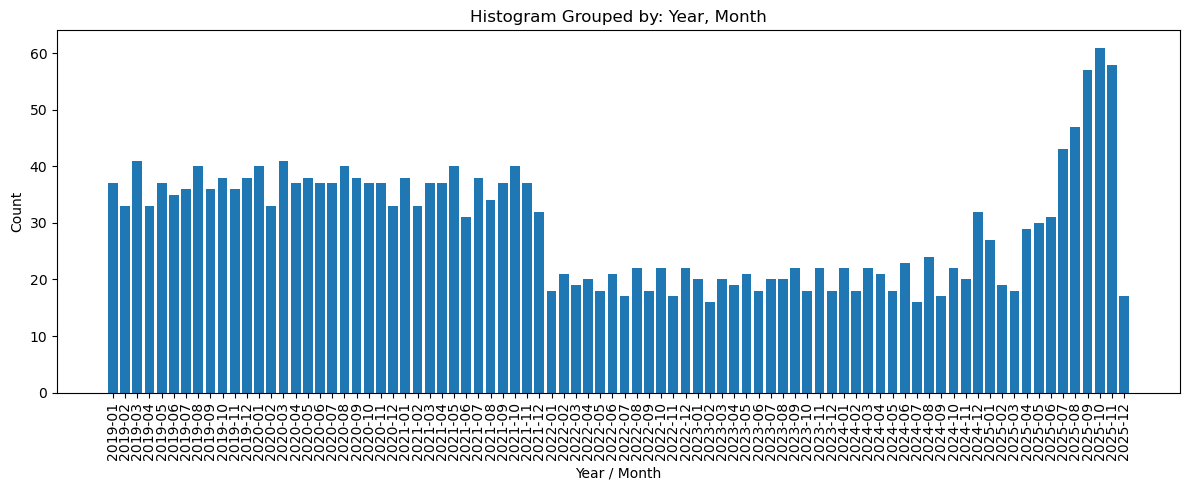

In [43]:
plot_date_histogram(items, group_by=("year", "month"))

## Bounding Boxes via flatgeobuf
Printing boudning boxes of the items that are returnded from a STAC search gives an overview of the spatial coverage.

This function writes a flatgeobuf file to further be used for interacting with the bbox geometries. Flatgeobuf is great for fast visualization of many polygons.

In [23]:
import geopandas as gpd
from shapely.geometry import box

def create_flatgeobuf_from_items(items, out_path, properties_to_keep=None):
    """
    Create a FlatGeobuf (.fgb) file with bounding-box polygons from pystac.Item objects.

    Parameters
    ----------
    items : list[pystac.Item]
        List of STAC items. Each must have `.bbox` and `.properties`.
    out_path : str
        Output FlatGeobuf path.
    properties_to_keep : list[str], optional
        If not None, only include these properties in the output.
    """
    
    records = []

    for item in items:
        # Ensure bbox exists
        if item.bbox is None or len(item.bbox) != 4:
            continue

        minx, miny, maxx, maxy = item.bbox
        poly = box(minx, miny, maxx, maxy)

        # Select properties
        if properties_to_keep:
            props = {k: item.properties.get(k) for k in properties_to_keep}
        else:
            # keep all properties, but ensure everything is serializable
            props = {}
            for k, v in item.properties.items():
                if isinstance(v, (str, int, float, bool)) or v is None:
                    props[k] = v
                else:
                    props[k] = str(v)

        props["geometry"] = poly
        records.append(props)

    # GeoDataFrame
    gdf = gpd.GeoDataFrame(records, geometry="geometry", crs="EPSG:4326")

    # Write FlatGeobuf
    gdf.to_file(out_path, driver="FlatGeobuf")

    print(f"Created {len(gdf)} bounding-box polygons in {out_path}")

This function simply maps the bounding boxes to give a first indication.

In [49]:
from typing import List, Optional, Sequence, Union, Dict, Any
import geopandas as gpd
from shapely.geometry import box, mapping
import folium
import math

def render_map_from_flatgeobuf(
    fgb_path: str,
    center: Optional[Sequence[float]] = None,
    zoom_start: int = 2,
    simplify_tolerance: Optional[float] = None,
    style_function: Optional[callable] = None
) -> folium.Map:
    """
    Render interactive Folium map from a FlatGeobuf of polygons.

    Parameters:
    fgb_path: str
        Path to the FlatGeobuf file created above.
    center: tuple(float, float) or None
        (lat, lon) center for the initial map view. If None, center is computed from dataset centroid.
    zoom_start: int
        Initial zoom level.
    simplify_tolerance: float or None
        If provided, geometries are simplified (units in degrees) to improve performance while rendering.
        Try values like 0.001 (small) to 0.01 (stronger).
    style_function: callable or None
        Optional function that receives a feature and returns a style dict for folium.GeoJson (e.g. color, weight).

    Returns:
    folium.Map
        The interactive folium Map containing the polygon layer.
    """

    # Read the flatgeobuf
    gdf = gpd.read_file(fgb_path)

    if gdf.empty:
        raise ValueError("FlatGeobuf file contains no features.")

    # Simplify geometry to speed up rendering
    if simplify_tolerance is not None and simplify_tolerance > 0:
        # preserve topology for polygons where possible
        gdf["geometry"] = gdf["geometry"].simplify(simplify_tolerance, preserve_topology=True)

    # Compute center if not provided (folium wants [lat, lon])
    if center is None:
        bounds = gdf.total_bounds  # [minx, miny, maxx, maxy]
        minx, miny, maxx, maxy = bounds
        center = [(miny + maxy) / 2.0, (minx + maxx) / 2.0]

    m = folium.Map(location=center, zoom_start=zoom_start, tiles="CartoDB positron")

    # Convert GeoDataFrame to GeoJSON-like mapping in memory and add to map
    # Use folium.GeoJson; for many features use a FeatureGroup to keep it organized
    fg = folium.FeatureGroup(name="Bounding boxes", overlay=True, control=True)

    # default style function if none provided
    if style_function is None:
        def style_function_default(feature):
            return {
                "fillColor": "#1f9e89",
                "color": "#000000",
                "weight": 1,
                "fillOpacity": 0.4,
            }
        style_function = style_function_default

    # Add polygons to the FeatureGroup
    folium.GeoJson(
        gdf,
        style_function=style_function
    ).add_to(fg)

    m.add_child(fg)
    folium.LayerControl().add_to(m)
    return m

Here the two functions are applied in sequence to create a flateobuf file and then map the polygons on an interactive map. 

*Note: In cases where a long timeseries is requested there are usually many overlaps. In this case the next visualization might help.* 

In [50]:
create_flatgeobuf_from_items(items = items, out_path = "./stacsearch_bboxes.fgb", properties_to_keep=None)
m = render_map_from_flatgeobuf("stacsearch_bboxes.fgb", simplify_tolerance=0.001)
#m.save("bboxes_map.html")
display(m)

Created 2483 bounding-box polygons in ./test_s1slc.fgb


## Heatmap via flatgeobuf
If there are many overlaps between the bounding boxes a heatmap can show where the hotspots of the counts of overlapping bounding boxes are.

This function computes a heatmap from a flatgeobuf file created with the function `create_flatgeobuf_from_items()` 

In [44]:
import geopandas as gpd
import numpy as np

def compute_bbox_heatmap(
    fgb_path,
    grid_size=50
):
    """
    Computes a fast heatmap (bbox density grid) from a FlatGeobuf file of bounding boxes.

    Parameters: 
        fgb_path: path to the flatgeobuf file
        grid_size: number of the grids to create in x and y direction (rasterization)
    Returns:
        heatmap: 2D numpy array (counts)
        extent:  (minx, miny, maxx, maxy)
    """
    gdf = gpd.read_file(fgb_path)

    # dataset bounds
    minx, miny, maxx, maxy = gdf.total_bounds

    # prepare grid
    x_bins = np.linspace(minx, maxx, grid_size + 1)
    y_bins = np.linspace(miny, maxy, grid_size + 1)

    heatmap = np.zeros((grid_size, grid_size), dtype=np.uint32)

    # fast loop through bboxes
    for geom in gdf.geometry:
        bxmin, bymin, bxmax, bymax = geom.bounds

        ix1 = np.searchsorted(x_bins, bxmin) - 1
        ix2 = np.searchsorted(x_bins, bxmax) - 1
        iy1 = np.searchsorted(y_bins, bymin) - 1
        iy2 = np.searchsorted(y_bins, bymax) - 1

        # increment all overlapping grid cells
        heatmap[iy1:iy2+1, ix1:ix2+1] += 1

    return heatmap, (minx, miny, maxx, maxy)

This function renders the heatmap created by `compute_bbox_heatmap()`.

In [45]:
import folium
import matplotlib.pyplot as plt
from folium.raster_layers import ImageOverlay

def map_bbox_heatmap(heatmap, extent, colormap="viridis", opacity=0.6):
    """
    Renders the heatmap as an ImageOverlay on a folium interactive map.

    Parameters: 
        heatmap: heatmap created by compute_bbox_heatmap
        extent: extent created by compute_bbox_heatmap
        colormap: a colormap known to matplotlib
        opacity: opacity between 0 and 1
    """
    minx, miny, maxx, maxy = extent

    fig, ax = plt.subplots(figsize=(6,6))
    ax.axis("off")

    # generate image array
    img = plt.cm.get_cmap(colormap)(heatmap / heatmap.max())

    # convert to uint8 for overlay
    img_uint8 = (img[:, :, :3] * 255).astype("uint8")

    m = folium.Map(
        location=[(miny + maxy) / 2, (minx + maxx) / 2],
        zoom_start=3,
        tiles="CartoDB positron"
    )

    ImageOverlay(
        image=img_uint8,
        bounds=[[miny, minx], [maxy, maxx]],
        opacity=opacity,
    ).add_to(m)

    folium.LayerControl().add_to(m)
    return m

Execute the function `compute_bbox_heatmap()` and `map_bbox_heatmap()`.

/dss/dsstbyfs02/scratch/06/di38laz/di38laz/tmp.rkjo7BaLxG/ipykernel_161795/3598274246.py:15: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  img = plt.cm.get_cmap(colormap)(heatmap / heatmap.max())



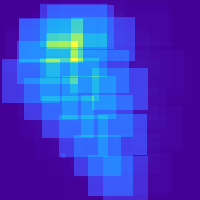

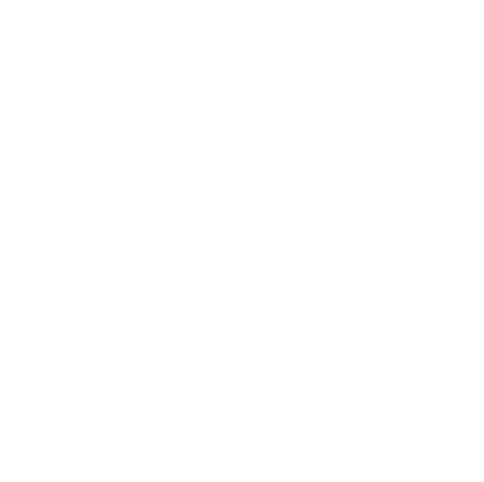

In [32]:
heatmap, extent = compute_bbox_heatmap("stacsearch_bboxes.fgb", grid_size=200)
m = map_bbox_heatmap(heatmap, extent)
#m.save("bbox_heatmap.html")
display(m)